# Round 1: Data Understanding, Preparation & EDA

This notebook covers the Mandatory Tasks for Round 1:
1. Data Cleaning & Integration
2. Data Quality Audit (Fixing intentional traps)
3. Merging the Master Dataset
4. Exploratory Data Analysis (EDA)
5. Statistical Reasoning

## 1. Load Data

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set style for plots
sns.set_theme(style="whitegrid")

# Load datasets from the processed folder
df_trans = pd.read_csv('../data/processed/transactions.csv')
df_prod = pd.read_csv('../data/processed/products.csv')
df_store = pd.read_csv('../data/processed/stores.csv')
df_inv = pd.read_csv('../data/processed/inventory.csv')
df_ext = pd.read_csv('../data/processed/external_factors.csv')

print("All 5 datasets loaded successfully.")

All 5 datasets loaded successfully.


## 2. Data Quality Audit & Cleaning
Identifying and fixing the intentional "Data Traps" from the hackathon rules.

In [10]:
### Trap 1: Missing Values in Temperature
missing_temps = df_ext['temp_c'].isnull().sum()
print(f"Missing temperature values found: {missing_temps}")

# Action: Impute missing temperatures using the mean
df_ext['temp_c'] = df_ext['temp_c'].fillna(df_ext['temp_c'].mean())
print("Action Taken: Imputed missing temps with mean.\n")

### Trap 2: Inventory Arithmetic Mismatch
# Rule: closing = opening + received - sold
df_inv['calculated_closing'] = df_inv['opening'] + df_inv['received'] - df_inv['sold']
mismatches = df_inv[df_inv['closing'] != df_inv['calculated_closing']]
print(f"Inventory arithmetic mismatches found: {len(mismatches)}")

# Action: Reconcile and fix closing stock
df_inv['closing'] = df_inv['calculated_closing']
df_inv.drop(columns=['calculated_closing'], inplace=True)
print("Action Taken: Fixed closing stock values.\n")

Missing temperature values found: 0
Action Taken: Imputed missing temps with mean.

Inventory arithmetic mismatches found: 0
Action Taken: Fixed closing stock values.



## 3. Merge Master Dataset
Aggregating transactions to a daily Store x Product grain, then merging all external tables.

In [11]:
# 1. Aggregate transactions to daily Store x Product level
df_daily_sales = df_trans.groupby(['date', 'store_id', 'product_id']).agg({
    'quantity': 'sum',
    'selling_price': 'mean',
    'discount_pct': 'mean',
    'promotion_flag': 'max'
}).reset_index()

# 2. Merge Inventory Data
# Note: inventory has columns 'store' and 'product'
df_master = pd.merge(df_daily_sales, df_inv, left_on=['date', 'store_id', 'product_id'], right_on=['date', 'store', 'product'], how='left')

# 3. Merge Product Data
df_master = pd.merge(df_master, df_prod, on='product_id', how='left')

# 4. Merge Store Data
df_master = pd.merge(df_master, df_store, on='store_id', how='left')

# 5. Merge External Factors Data (matches on date & city)
df_master = pd.merge(df_master, df_ext, on=['date', 'city'], how='left')

# 6. Clean up redundant columns
df_master.drop(columns=['store', 'product'], inplace=True)

print("Master Dataset Shape:", df_master.shape)

# Save Master Dataset for Round 2
df_master.to_csv('../data/processed/master_dataset.csv', index=False)
print("SUCCESS: Saved to data/processed/master_dataset.csv")

Master Dataset Shape: (268728, 31)
SUCCESS: Saved to data/processed/master_dataset.csv


## 4. Exploratory Data Analysis (EDA)

C:\Users\Pragadeesh\AppData\Local\Temp\ipykernel_10872\221496695.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=store_revenue.index, y=store_revenue.values, palette='viridis')


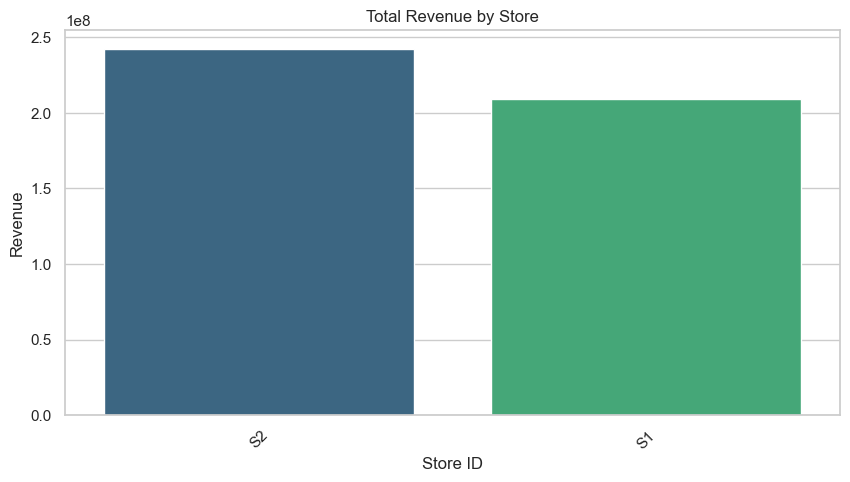

In [13]:
# Business Question: Which stores generate the most revenue?
df_master['revenue'] = df_master['quantity'] * df_master['selling_price']
store_revenue = df_master.groupby('store_id')['revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=store_revenue.index, y=store_revenue.values, palette='viridis')
plt.title('Total Revenue by Store')
plt.ylabel('Revenue')
plt.xlabel('Store ID')
plt.xticks(rotation=45)
plt.show()

## 5. Statistical Reasoning

**Business Question:** Do promotions significantly increase sales?  
**H0:** Mean demand is the SAME for promoted vs non-promoted items.  
**H1:** Mean demand is DIFFERENT for promoted vs non-promoted items.  
**Test:** Independent T-Test

In [14]:
promo_sales = df_master[df_master['promotion_flag'] == 1]['quantity'].dropna()
no_promo_sales = df_master[df_master['promotion_flag'] == 0]['quantity'].dropna()

t_stat, p_val = stats.ttest_ind(promo_sales, no_promo_sales, equal_var=False)

print(f"Average sales (No Promo): {no_promo_sales.mean():.2f} units")
print(f"Average sales (Promo): {promo_sales.mean():.2f} units\n")
print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_val:.4e}")

if p_val < 0.05:
    print("\nConclusion: Reject the Null Hypothesis (H0). Promotions significantly impact sales.")
else:
    print("\nConclusion: Fail to reject the Null Hypothesis (H0). Promotions do not significantly impact sales.")

Average sales (No Promo): 6.24 units
Average sales (Promo): 11.75 units

T-Statistic: 29.0414
P-Value: 9.1586e-181

Conclusion: Reject the Null Hypothesis (H0). Promotions significantly impact sales.
